# 02 — Value iteration (dynamic programming)

Goal: compute, for each letter, **the best possible way to draw it**. This optimum is the reference
for the next steps: we will measure how close Q-learning, SARSA and Monte Carlo get to it.

Dynamic programming can do this because it **knows the model** of the environment (built by
`build_model()` in notebook 01). The model-free methods of the next steps will not have it.

## The equations

**Bellman optimality equation** (course, chapter 4):

$$v_*(s) = \max_a \sum_{s', r} p(s', r \mid s, a)\,\big[r + \gamma\, v_*(s')\big]$$

Our environment is **deterministic**: each pair $(s, a)$ leads to a single next state $s'(s,a)$
and a single reward $r(s,a)$, with probability 1. The sum therefore has a single term:

$$v_*(s) = \max_a \big[r(s,a) + \gamma\, v_*(s'(s,a))\big]$$

After STOP (a terminal transition) there is no future, so $v(s')$ is replaced by $0$.

**Value iteration** starts from $v_0(s) = 0$ for every state and repeats the update:

$$v_{k+1}(s) = \max_a \big[r(s,a) + \gamma\, v_k(s'(s,a))\big]$$

until the values stop changing:

$$\Delta_k = \max_s \big|v_{k+1}(s) - v_k(s)\big| < \theta \qquad (\theta = 10^{-8})$$

The **optimal policy** is then read off: in each state, take the action that gives the maximum:

$$\pi_*(s) = \arg\max_a \big[r(s,a) + \gamma\, v_*(s'(s,a))\big]$$

**Implementation note.** The course notebook (Frozen Lake) loops over the states one by one and
overwrites $V(s)$ immediately (*in-place* version). With up to 204,800 states, a Python loop would be
slow, so `src/dynamic_programming.py` updates all the states at once from the previous $V$ with numpy
arrays (*two-array* version, Sutton & Barto, section 4.1). Both versions converge to the same $v_*$.

In [1]:
import sys
sys.path.insert(0, "..")

import csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image

from src.letters import make_letter, TRAINING_LETTERS
from src.environment import LetterWritingEnv, action_name
from src.dynamic_programming import value_iteration
from src.evaluation import play_policy
from src.visualization import plot_episodes, animate_episodes, SURFACE, TEXT, MUTED

GAMMA = 0.99

## 1. One letter in detail: L

We run value iteration on L and look at what happens at each iteration.

In [2]:
env = LetterWritingEnv("L")
res = value_iteration(env, gamma=GAMMA)

print(f"states: {env.n_states:,}   iterations: {len(res['deltas'])}")
for k, delta in enumerate(res["deltas"], start=1):
    print(f"  iteration {k:>2}:  delta = {delta:.6f}")

for start in env.letter.start_points:
    s0 = env.encode(*start, 0, 0)
    print(f"\nv*(start {start}) = {res['V'][s0]:.3f}")
    print("optimal first action:", action_name(res["policy"][s0]))

states: 6,400   iterations: 13
  iteration  1:  delta = 2.000000
  iteration  2:  delta = 1.980000
  iteration  3:  delta = 1.960200
  iteration  4:  delta = 1.940598
  iteration  5:  delta = 1.921192
  iteration  6:  delta = 1.901980
  iteration  7:  delta = 1.882960
  iteration  8:  delta = 1.864131
  iteration  9:  delta = 1.845489
  iteration 10:  delta = 1.827034
  iteration 11:  delta = 1.808764
  iteration 12:  delta = 1.790677
  iteration 13:  delta = 0.000000

v*(start (0, 0)) = 8.018
optimal first action: down (pen down)

v*(start (4, 3)) = 8.018
optimal first action: left (pen down)


**How to read this.** After $k$ iterations, $v_k(s)$ is the best return the agent can get in at
most $k$ steps. As long as $k$ is too small to finish the letter from some states, those states
discover at iteration $k$ that they can now finish and collect the STOP bonus: their value jumps,
so $\Delta$ stays close to 2. Once $k$ is larger than the longest optimal path, the values
**stop changing completely** ($\Delta = 0$). This is different from Frozen Lake, where $\Delta$
decreases gradually because of the random slipping.
Because the environment is deterministic and every optimal path is short, value iteration
converges *exactly* after a few iterations instead of approaching $v_*$ slowly.

## 2. The 10 letters

For each letter: build the model, run value iteration, then play the optimal policy from each
natural starting point. We check that the discounted return obtained by playing the policy equals
$v_*(\text{start})$ — a good test that the policy and the values agree.

In [3]:
results, rows = {}, []
for name in TRAINING_LETTERS:
    env = LetterWritingEnv(name)
    res = value_iteration(env, gamma=GAMMA)
    episodes = {}
    for start in env.letter.start_points:
        ep = play_policy(env, res["policy"], start, gamma=GAMMA)
        v_star = res["V"][env.encode(*start, 0, 0)]
        assert np.isclose(ep["discounted_return"], v_star), (name, start)
        episodes[start] = ep
        rows.append({"letter": name, "start": start, "segments": env.k, "v_star": round(float(v_star), 4),
                     "total_reward": round(ep["total_reward"], 4), "steps": ep["steps"],
                     "strokes": ep["strokes"], "off_letter": ep["off_letter"], "completed": ep["completed"]})
    results[name] = {"env": env, "res": res, "episodes": episodes}

print(f"{'letter':<7}{'segments':>9}{'states':>10}{'model (s)':>11}{'VI (s)':>8}{'iterations':>12}")
for name, r in results.items():
    env, res = r["env"], r["res"]
    print(f"{name:<7}{env.k:>9}{env.n_states:>10,}{res['model_time']:>11.1f}{res['solve_time']:>8.1f}{len(res['deltas']):>12}")

print(f"\n{'letter':<7}{'start':<9}{'v*':>8}{'reward':>8}{'steps':>7}{'strokes':>9}{'off':>5}{'completed':>11}")
for row in rows:
    print(f"{row['letter']:<7}{str(row['start']):<9}{row['v_star']:>8.3f}{row['total_reward']:>8.2f}"
          f"{row['steps']:>7}{row['strokes']:>9}{row['off_letter']:>5}{str(row['completed']):>11}")

with open("../results/02_optimal_returns.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)
print("\nsaved: results/02_optimal_returns.csv")

letter  segments    states  model (s)  VI (s)  iterations
I              8    12,800        0.2     0.1          15
L              7     6,400        0.1     0.0          13
T              8    12,800        0.2     0.0          16
E             12   204,800        2.7     1.1          21
F              9    25,600        0.3     0.1          17
H             12   204,800        2.6     1.2          23
N             12   204,800        2.8     1.0          19
Z             12   204,800        2.9     1.0          19
V              8    12,800        0.2     0.0          15
X              8    12,800        0.2     0.0          16

letter start          v*  reward  steps  strokes  off  completed
I      (0, 1)      8.690    9.20     11        1    0       True
I      (0, 3)      8.690    9.20     11        1    0       True
I      (4, 1)      8.690    9.20     11        1    0       True
I      (4, 3)      8.690    9.20     11        1    0       True
L      (0, 0)      8.018    8.35    

## 3. The optimal drawings

Each letter drawn by the optimal policy from its first natural starting point.

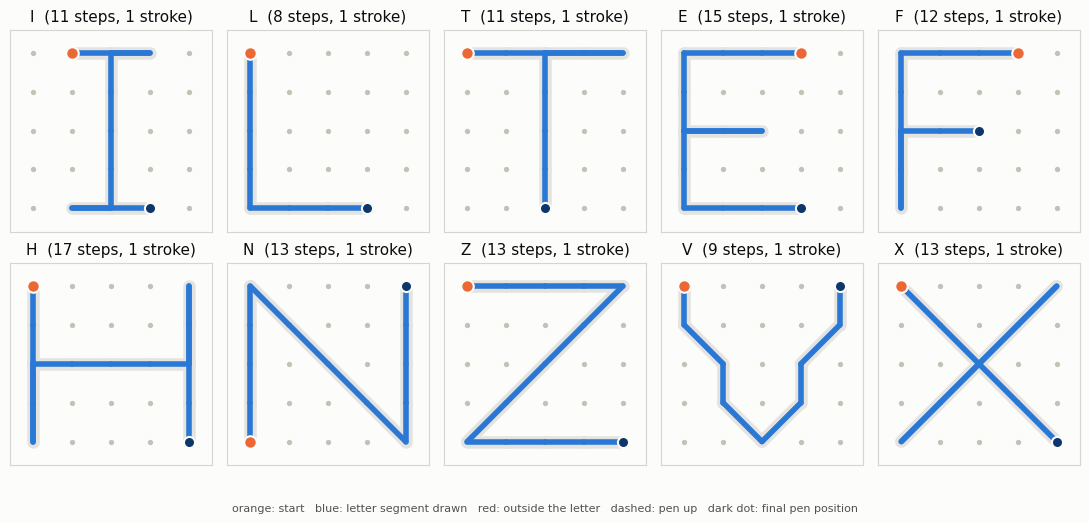

In [4]:
panels = []
for name, r in results.items():
    start = r["env"].letter.start_points[0]
    ep = r["episodes"][start]
    panels.append((r["env"].letter, ep["history"], f"{name}  ({ep['steps']} steps, {ep['strokes']} stroke{'s' * (ep['strokes'] > 1)})"))

plot_episodes(panels, path="../results/02_optimal_drawings.png")
plt.show()

The static picture hides the **order** of the moves. The animation shows it, step by step
(it is saved in `results/` and can be reused in the presentation).

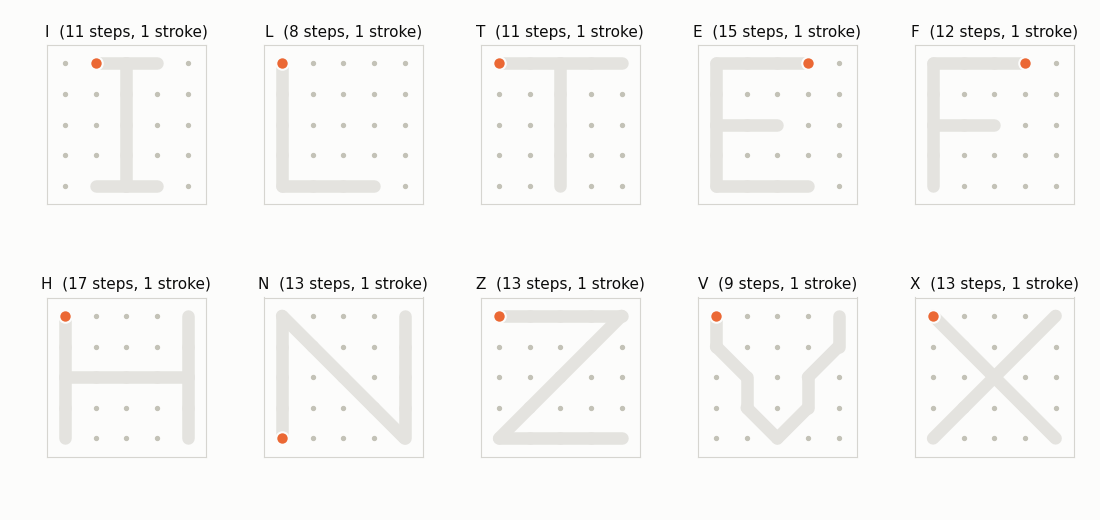

In [5]:
animate_episodes(panels, "../results/02_optimal_drawings.gif")
Image(filename="../results/02_optimal_drawings.gif")

## 4. Does the starting point matter? The letter E

E has three natural starting points. The optimal policy adapts the drawing order to where the pen starts.

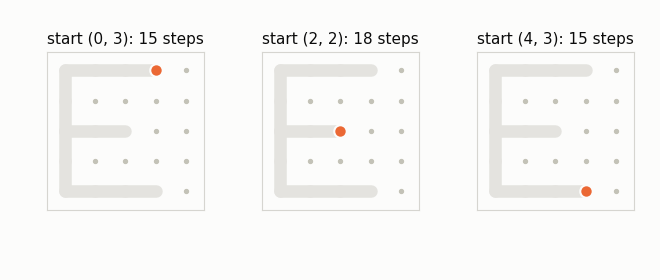

In [6]:
r = results["E"]
panels_e = [(r["env"].letter, ep["history"], f"start {start}: {ep['steps']} steps")
            for start, ep in r["episodes"].items()]
animate_episodes(panels_e, "../results/02_E_starts.gif", ncols=3)
Image(filename="../results/02_E_starts.gif")

## 5. Convergence

$\Delta_k = \max_s |v_{k+1}(s) - v_k(s)|$ at each iteration, for every letter (one colour per number
of segments). The panel on the right gives the number of iterations needed until $\Delta = 0$.

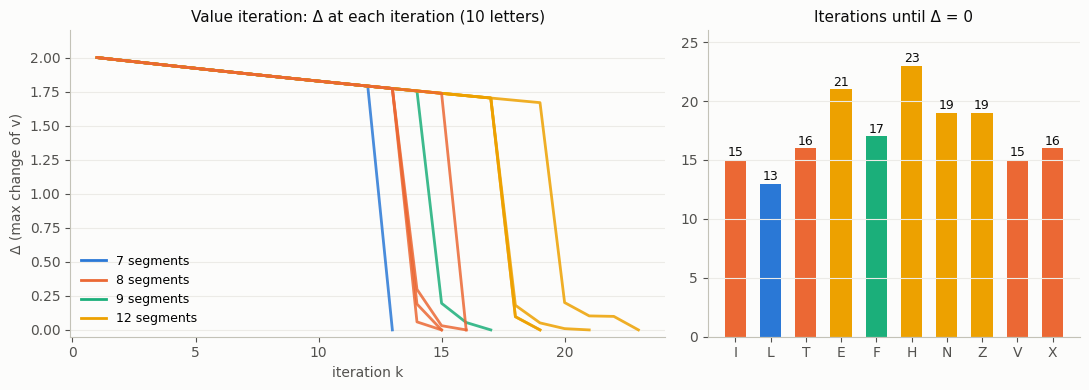

In [7]:
groups = sorted({r["env"].k for r in results.values()})
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # one colour per number of segments
color = {k: palette[i] for i, k in enumerate(groups)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), facecolor=SURFACE, gridspec_kw={"width_ratios": [1.6, 1]})
for name, r in results.items():
    deltas = r["res"]["deltas"]
    ax1.plot(range(1, len(deltas) + 1), deltas, color=color[r["env"].k], lw=2, alpha=0.85)
handles = [plt.Line2D([], [], color=color[k], lw=2) for k in groups]
ax1.legend(handles, [f"{k} segments" for k in groups], frameon=False, fontsize=9, loc="lower left")
ax1.set_xlabel("iteration k", color=MUTED)
ax1.set_ylabel("Δ (max change of v)", color=MUTED)
ax1.set_title("Value iteration: Δ at each iteration (10 letters)", color=TEXT, fontsize=11)
ax1.set_ylim(-0.05, 2.2)

names = list(results)
iters = [len(results[n]["res"]["deltas"]) for n in names]
ax2.bar(names, iters, color=[color[results[n]["env"].k] for n in names], width=0.6)
for x, y in zip(names, iters):
    ax2.text(x, y + 0.3, str(y), ha="center", fontsize=9, color=TEXT)
ax2.set_title("Iterations until Δ = 0", color=TEXT, fontsize=11)
ax2.set_ylim(0, max(iters) + 3)

for ax in (ax1, ax2):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color="#ecebe7", lw=0.8)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
fig.tight_layout()
fig.savefig("../results/02_convergence.png", dpi=150, facecolor=SURFACE)
plt.show()

## What to notice

- **Every letter is drawn completely, with no segment outside the letter**, from every starting point.
- **The optimal agent never lifts the pen: every letter is drawn in a single stroke.** When it reaches
  the end of a stroke, it goes back over segments already drawn (−0.05 per move) rather than lifting
  the pen (−0.3 for a new stroke, plus the pen-up moves). For example, X is drawn in one stroke by going
  back to the centre. A person would rather lift the pen: the reward defines the writing *style*.
  We will vary the −0.3 / −0.05 ratio in the reward experiments (step 6).
- **The starting point matters**: for E, starting from the middle bar (2, 2) costs more steps than
  starting from a corner, so $v_*$ is lower.
- **Convergence is exact and fast** (13 to 23 iterations): after $k$ iterations, $v_k$ is the best return
  reachable in $k$ steps; once $k$ is larger than the longest optimal path, nothing changes any more.
  The letters with more segments need more iterations because their optimal paths are longer.
- **Computation time**: building the model is the slow part (a few seconds for the 12-segment letters);
  value iteration itself takes about one second. This is still small, but it grows with 2^(segments):
  the *curse of dimensionality* mentioned in the course (chapter 4, downsides of DP).